In [25]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from pathlib import Path

In [8]:
def diezmado(imagen, factor):
    """
    Diezmado simple: toma 1 pixel cada 'factor'
    Se asume que la imagen ya ha sido suavizada antes.
    """
    if factor < 1:
        raise ValueError("El factor de diezmado debe ser un entero >= 1")
    return imagen[::factor, ::factor]

In [9]:
def suavizado_pasabajo(imagen, metodo="gauss", orden=3):
    """
    Aplica un filtro paso bajo antes del diezmado para evitar aliasing.
    metodo = "gauss" | "media"
    """
    if metodo == "gauss":
        # Filtro Gaussiano tamaño orden
        filtrada = cv.GaussianBlur(imagen, (orden,orden), 0)
    else:
        # Filtro de media tamaño orden
        filtrada = cv.blur(imagen, (orden,orden))
    
    return filtrada

In [10]:
def diezmado_anti_aliasing(imagen, factor, metodo_filtro="gauss"):
    """
    Proceso completo:
      1. Filtrado paso bajo (anti-aliasing)
      2. Diezmado por factor f
    """
    img_suav = suavizado_pasabajo(imagen, metodo=metodo_filtro, orden=3)
    img_diez = diezmado(img_suav, factor)
    return img_suav, img_diez


(-0.5, 861.5, 1132.5, -0.5)

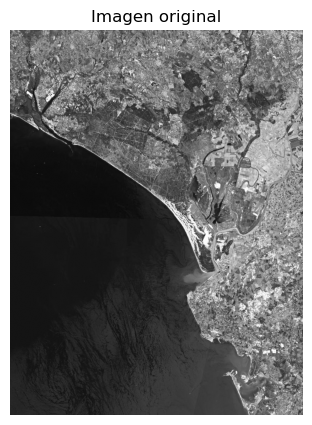

In [28]:
img_ori = cv.imread("primeraImagen.jpeg")
img= cv.cvtColor(img_ori, cv.COLOR_BGR2GRAY)
factor = 4 
plt.figure(figsize=(5,5))
plt.imshow(img, cmap='gray')
plt.title("Imagen original")
plt.axis('off')

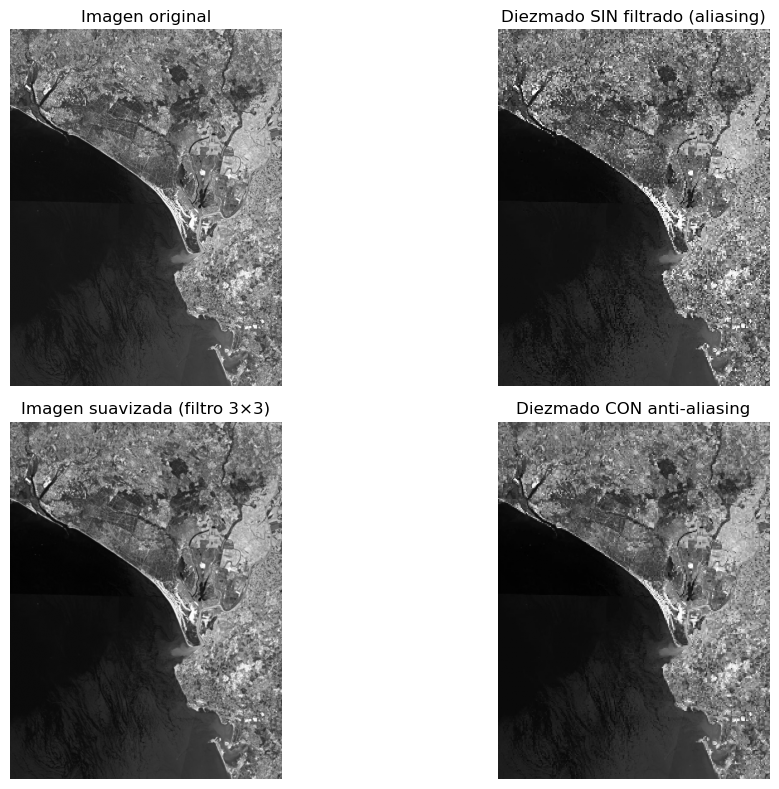

In [29]:
factor = 4

img_diez_sin = diezmado(img, factor)

img_suav, img_diez_con = diezmado_anti_aliasing(img, factor)

plt.figure(figsize=(12,8))

plt.subplot(2,2,1)
plt.imshow(img, cmap='gray')
plt.title("Imagen original")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(img_diez_sin, cmap='gray')
plt.title("Diezmado SIN filtrado (aliasing)")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(img_suav, cmap='gray')
plt.title("Imagen suavizada (filtro 3×3)")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(img_diez_con, cmap='gray')
plt.title("Diezmado CON anti-aliasing")
plt.axis("off")

plt.tight_layout()
plt.show()


In [30]:
#TAREA 23

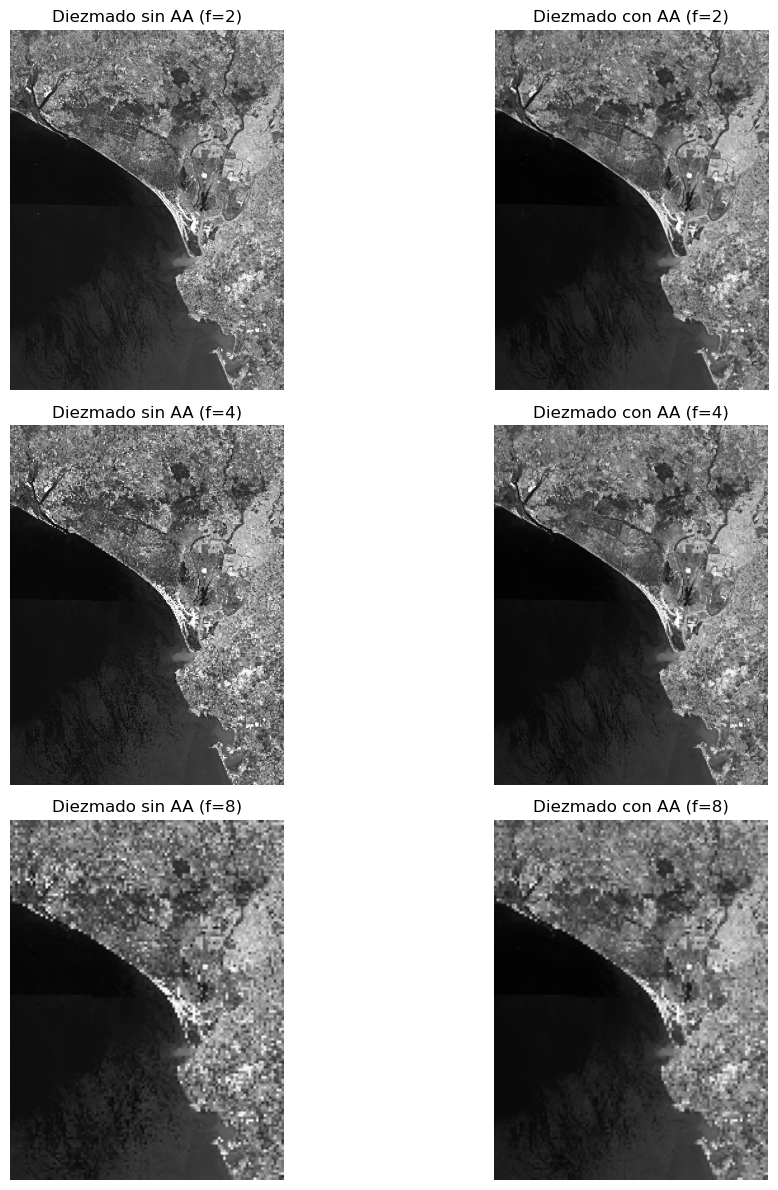

In [31]:
factores = [2, 4, 8]

plt.figure(figsize=(12, 12))

i = 1
for f in factores:
    img_diez = diezmado(img, f)
    img_suav, img_diez_aa = diezmado_anti_aliasing(img, f)

    plt.subplot(3, 2, i)
    plt.imshow(img_diez, cmap='gray')
    plt.title(f"Diezmado sin AA (f={f})")
    plt.axis("off")
    i += 1

    plt.subplot(3, 2, i)
    plt.imshow(img_diez_aa, cmap='gray')
    plt.title(f"Diezmado con AA (f={f})")
    plt.axis("off")
    i += 1

plt.tight_layout()
plt.show()


In [32]:
#A mayor factor de diezmado, la imagen pierde más detalle y aumenta la pixelación, siendo el anti-aliasing esencial para evitar artefactos visuales.

In [33]:
#TAREA 24

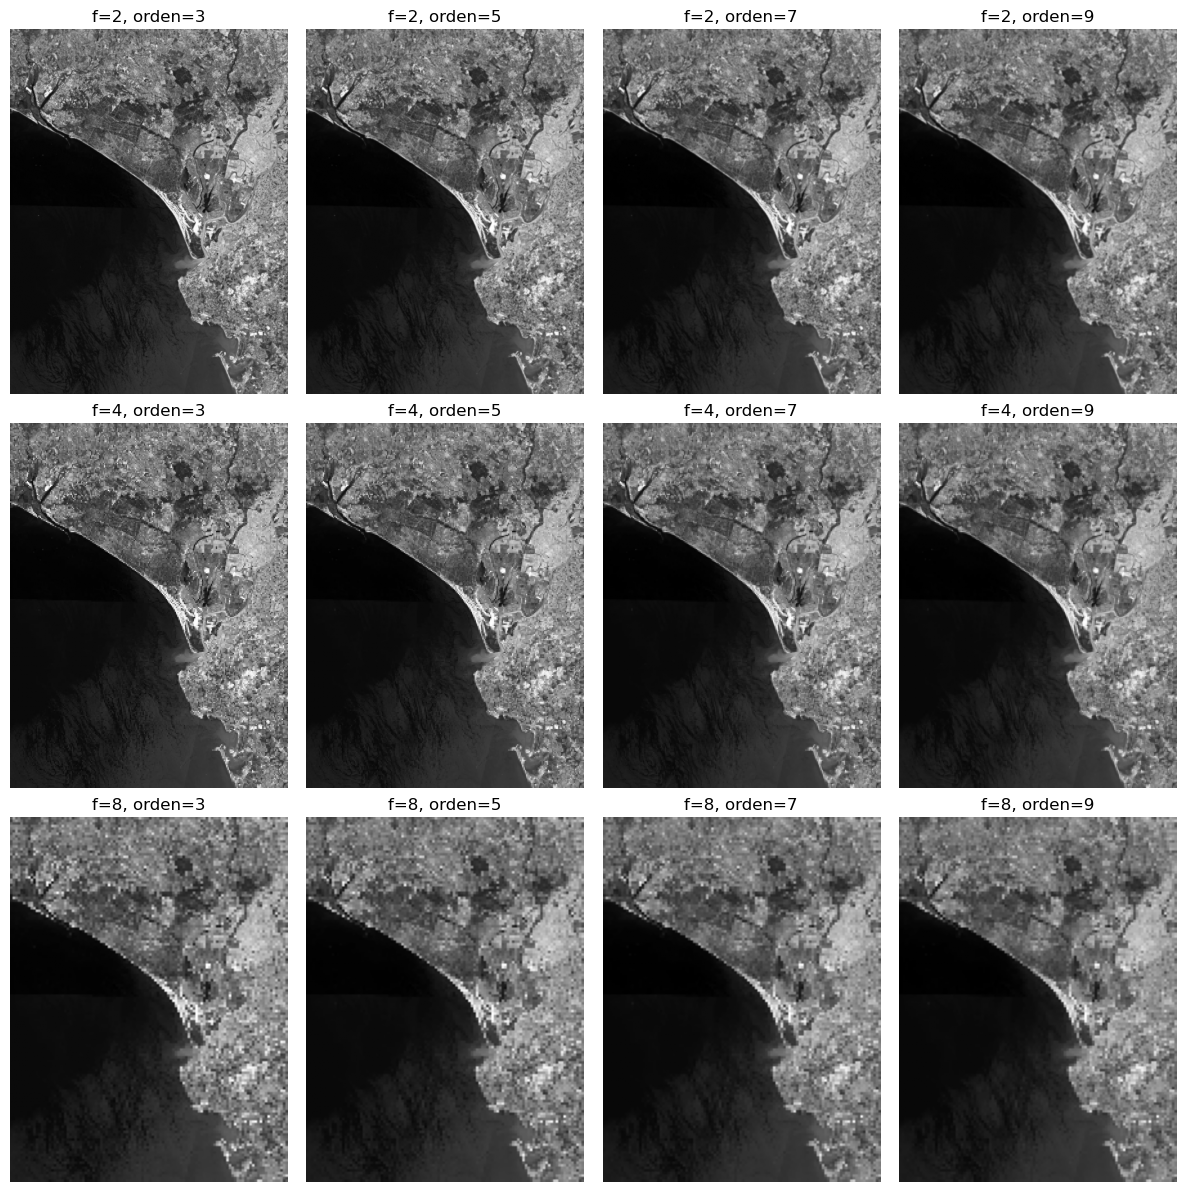

In [43]:
factores = [2, 4, 8]
ordenes = [3, 5, 7, 9]

plt.figure(figsize=(12, 12))
i = 1

for f in factores:
    for o in ordenes:
        img_suav = suavizado_pasabajo(img, metodo="gauss", orden=o)
        res = diezmado(img_suav, f)
        plt.subplot(len(factores), len(ordenes), i)
        plt.imshow(res, cmap='gray')
        plt.title(f"f={f}, orden={o}")
        plt.axis("off")
        i += 1

plt.tight_layout()
plt.show()

In [35]:
#Cuanto mayor es el filtro, más se suaviza la imagen y menos se notan los defectos del diezmado.

In [38]:
#TAREA 25

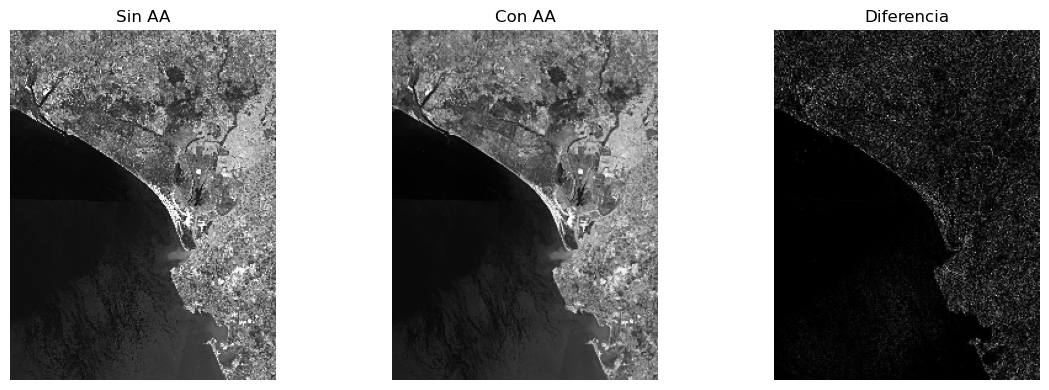

In [39]:
img_sin = diezmado(img, factor)
img_suav, img_con = diezmado_anti_aliasing(img, factor)

diff = cv.absdiff(img_sin, img_con)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img_sin, cmap='gray')
plt.title("Sin AA")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(img_con, cmap='gray')
plt.title("Con AA")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(diff, cmap='gray')
plt.title("Diferencia")
plt.axis("off")

plt.tight_layout()
plt.show()


In [40]:
#La imagen de diferencia resalta las zonas donde el diezmado sin filtro introduce errores: aparecen claros en áreas con muchos detalles o luces, que el filtrado suaviza y por eso cambian más.

In [41]:
#TAREA26

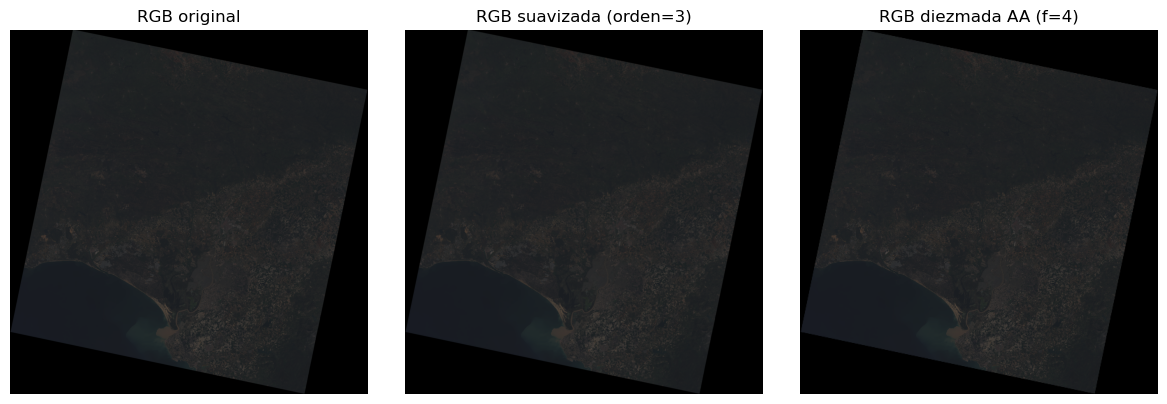

In [42]:
R = cv.imread("RGB/Landsat_C_04-11_R.png", cv.IMREAD_GRAYSCALE)
G = cv.imread("RGB/Landsat_C_03-11_G.png", cv.IMREAD_GRAYSCALE)
B = cv.imread("RGB/Landsat_C_02-11_B.png", cv.IMREAD_GRAYSCALE)

rgb = np.dstack([R, G, B]).astype(np.uint8)

factor = 4

R_s, R_d = diezmado_anti_aliasing(R, factor)
G_s, G_d = diezmado_anti_aliasing(G, factor)
B_s, B_d = diezmado_anti_aliasing(B, factor)

rgb_suav = np.dstack([R_s, G_s, B_s]).astype(np.uint8)
rgb_diez = np.dstack([R_d, G_d, B_d]).astype(np.uint8)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(rgb); plt.title("RGB original"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(rgb_suav); plt.title("RGB suavizada (orden=3)"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(rgb_diez); plt.title(f"RGB diezmada AA (f={factor})"); plt.axis("off")
plt.tight_layout(); plt.show()
